# ModelAtlas: exploring the model graph

A short, read-only tour of model families, licenses and training datasets.
Run all cells from the repository root with the Neo4j database and API running.
Install `requirements-notebook.txt` with **Python 3.12 or newer**.

The saved run uses the full graph, not the small test fixture. Its dataset-card
loader is PR #5 at commit `4a8966dddcfe478805a3fdddde8e8f7cef9922f6`.
The two downloaded data revisions are shown below. This draft should be merged
after #5, #7 and #8; it does not merge those PRs itself.

## 1. Setup

The password comes from `.env` or the environment and is never displayed.
Defaults are `bolt://localhost:7687` and `http://127.0.0.1/api`.
Set `NEO4J_NOTEBOOK_URI` and `MODELATLAS_API_URL` to use other local ports.
Reads use READ sessions, a 10-second query timeout and bounded result lists.

In [1]:
from time import perf_counter

started = perf_counter()

import json
import os
import platform
from pathlib import Path
from urllib.parse import quote
from typing import Any

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from dotenv import dotenv_values
from IPython.display import display
from neo4j import READ_ACCESS, GraphDatabase, Query

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

root = Path.cwd()
config = dotenv_values(root / ".env")
password = os.getenv("NEO4J_PASSWORD") or config.get("NEO4J_PASSWORD")
if not password:
    raise RuntimeError("Set NEO4J_PASSWORD in .env before running this notebook.")
uri = os.getenv("NEO4J_NOTEBOOK_URI") or config.get("NEO4J_NOTEBOOK_URI", "bolt://localhost:7687")
user = os.getenv("NEO4J_USER") or config.get("NEO4J_USER", "neo4j")
database = os.getenv("NEO4J_DATABASE") or config.get("NEO4J_DATABASE", "neo4j")
api_url = os.getenv("MODELATLAS_API_URL") or config.get("MODELATLAS_API_URL", "http://127.0.0.1/api")
driver = GraphDatabase.driver(uri, auth=(user, password), connection_timeout=10)
driver.verify_connectivity()
http = requests.Session()
http.trust_env = False  # Local requests must not go through a system HTTP proxy.


def read(cypher: str, **params: Any) -> list[dict[str, Any]]:
    """Fetch a bounded query result through a read-only session."""
    with driver.session(database=database, default_access_mode=READ_ACCESS) as session:
        return session.run(Query(cypher, timeout=10), params).data()


def api(path: str, **params: Any) -> dict[str, Any]:
    """Call the running API, failing clearly on an unsuccessful response."""
    response = http.get(f"{api_url.rstrip('/')}/{path.lstrip('/')}", params=params, timeout=15)
    response.raise_for_status()
    return response.json()


assert api("/health")["status"] == "ok"
data_dir = Path(os.getenv("MODELATLAS_DATA_DIR") or config.get("MODELATLAS_DATA_DIR", root / "data"))
provenance = []
for source in ("model_cards", "dataset_cards"):
    manifest = data_dir / "raw" / source / "manifest.json"
    revision = (
        json.loads(manifest.read_text(encoding="utf-8"))["commit"] if manifest.exists() else "not available locally"
    )
    provenance.append({"source": source, "dump commit": revision})
display(pd.DataFrame(provenance))
print(f"Python {platform.python_version()} | matplotlib {matplotlib.__version__} | networkx {nx.__version__}")


,source,dump commit
0,model_cards,99b6ce9d9d47f796700745ed9630556c91c00439
1,dataset_cards,a20ebd23b0e74614bd0458f264e46b31df52718a


Python 3.12.14 | matplotlib 3.11.2 | networkx 3.7


## 2. Graph overview

These are counts from the live database. `Unlisted` is an extra label on
a `Model`, so label counts overlap and should not be added as distinct entities.
Relationships include the dataset-card links when the second source is loaded.

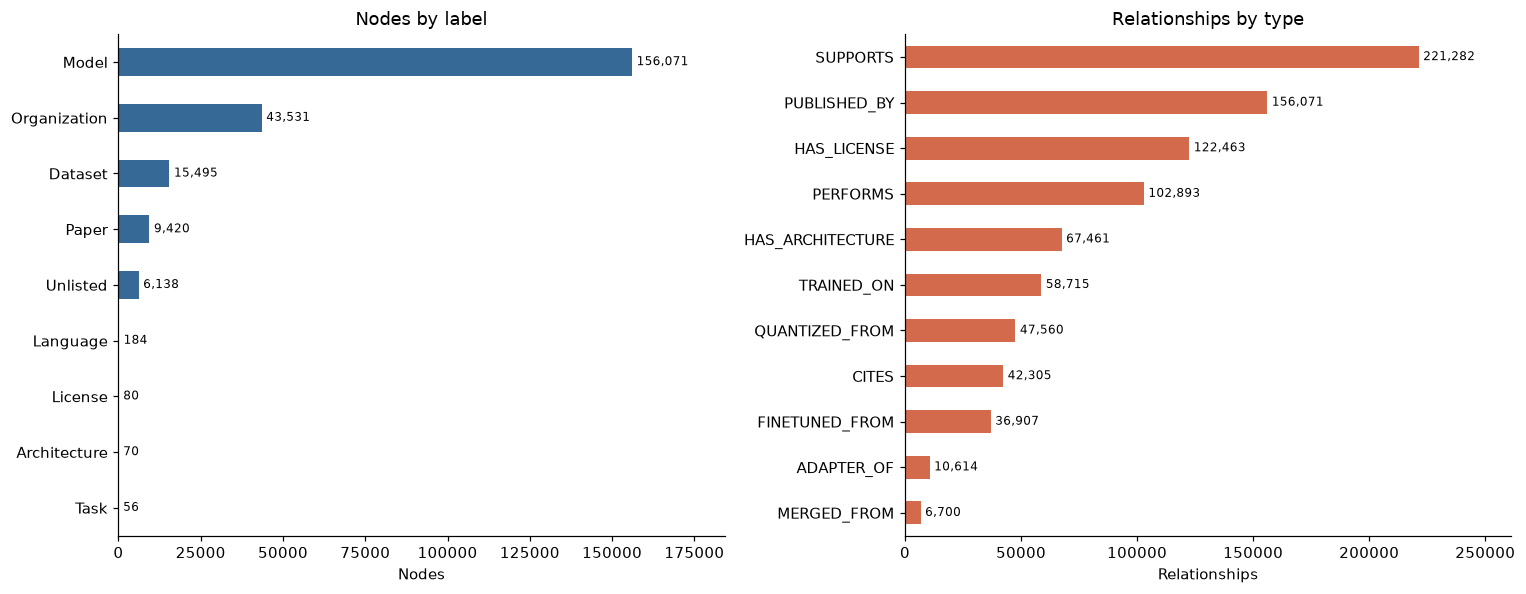

API and database agree: 156,071 Model nodes.


In [2]:
node_counts = pd.DataFrame(
    read(
        "MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes "
        "ORDER BY nodes DESC, label LIMIT $limit",
        limit=50,
    )
)
relation_counts = pd.DataFrame(
    read(
        "MATCH ()-[r]->() RETURN type(r) AS relation, count(*) AS links " "ORDER BY links DESC, relation LIMIT $limit",
        limit=50,
    )
)
assert not node_counts.empty and not relation_counts.empty, "Load the full graph before running the demo."
model_count = int(node_counts.set_index("label").loc["Model", "nodes"])
assert api("/stats")["models"] == model_count, "The API and driver must point to the same graph."

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
node_counts.iloc[::-1].plot.barh(x="label", y="nodes", ax=axes[0], color="#376996", legend=False)
relation_counts.iloc[::-1].plot.barh(x="relation", y="links", ax=axes[1], color="#d46a4c", legend=False)
axes[0].set(title="Nodes by label", xlabel="Nodes", ylabel="")
axes[1].set(title="Relationships by type", xlabel="Relationships", ylabel="")
for axis in axes:
    axis.bar_label(axis.containers[0], fmt="{:,.0f}", padding=3, fontsize=8)
axes[0].set_xlim(0, node_counts["nodes"].max() * 1.18)
axes[1].set_xlim(0, relation_counts["links"].max() * 1.18)
fig.tight_layout()
plt.show()
print(f"API and database agree: {model_count:,} Model nodes.")


## 3. Lineage statistics

`lineage_depth` is the longest chain above a model; roots have depth zero.
`descendant_count` counts distinct descendants and is precomputed during ETL.
Reading the stored value avoids traversing every family again in this demo.
The descendant chart uses powers-of-ten bins and a logarithmic count axis;
zero descendants have their own bin.

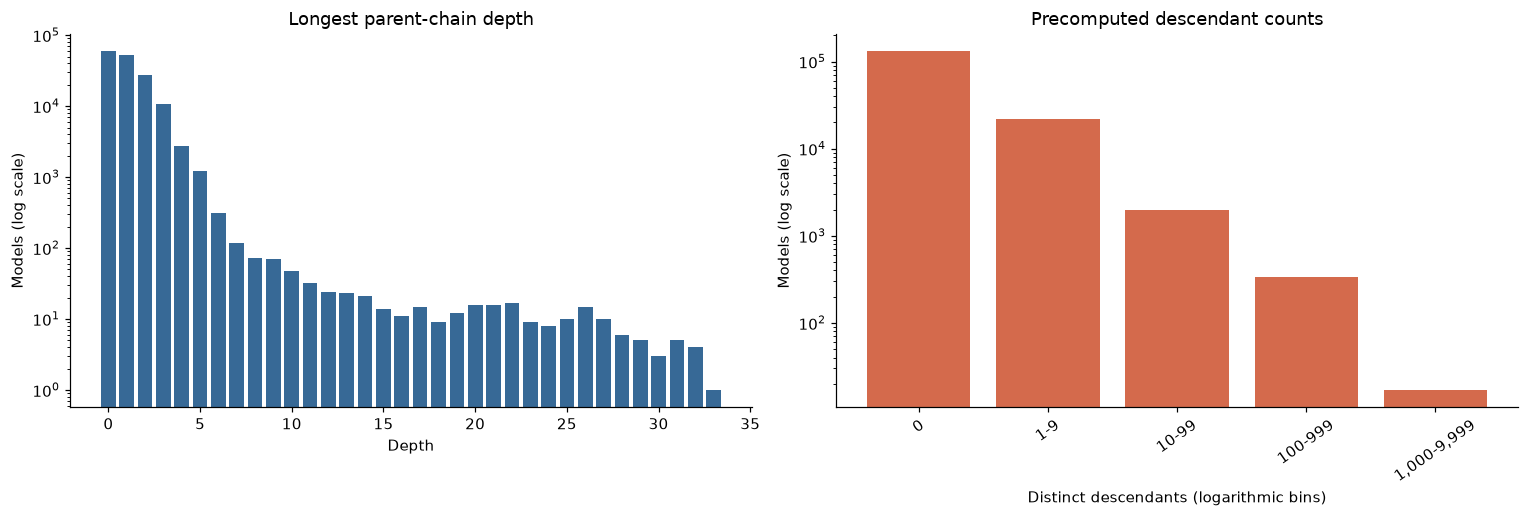

99.42% of models with a depth value have depth at most five.


In [3]:
depth_counts = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.lineage_depth IS NOT NULL "
        "RETURN m.lineage_depth AS depth, count(*) AS models ORDER BY depth LIMIT $limit",
        limit=200,
    )
)
descendant_bins = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.descendant_count IS NOT NULL "
        "WITH CASE WHEN m.descendant_count = 0 THEN 0 "
        "ELSE toInteger(floor(log10(toFloat(m.descendant_count)))) + 1 END AS bucket "
        "RETURN bucket, count(*) AS models ORDER BY bucket LIMIT $limit",
        limit=30,
    )
)
descendant_bins["range"] = descendant_bins["bucket"].map(
    lambda bucket: "0" if bucket == 0 else f"{10 ** (bucket - 1):,}-{10 ** bucket - 1:,}"
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(depth_counts["depth"], depth_counts["models"], color="#376996")
axes[0].set(title="Longest parent-chain depth", xlabel="Depth", ylabel="Models (log scale)", yscale="log")
axes[1].bar(descendant_bins["range"], descendant_bins["models"], color="#d46a4c")
axes[1].set(
    title="Precomputed descendant counts",
    xlabel="Distinct descendants (logarithmic bins)",
    ylabel="Models (log scale)",
    yscale="log",
)
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()
share_shallow = depth_counts.loc[depth_counts["depth"] <= 5, "models"].sum() / depth_counts["models"].sum()
print(f"{share_shallow:.2%} of models with a depth value have depth at most five.")


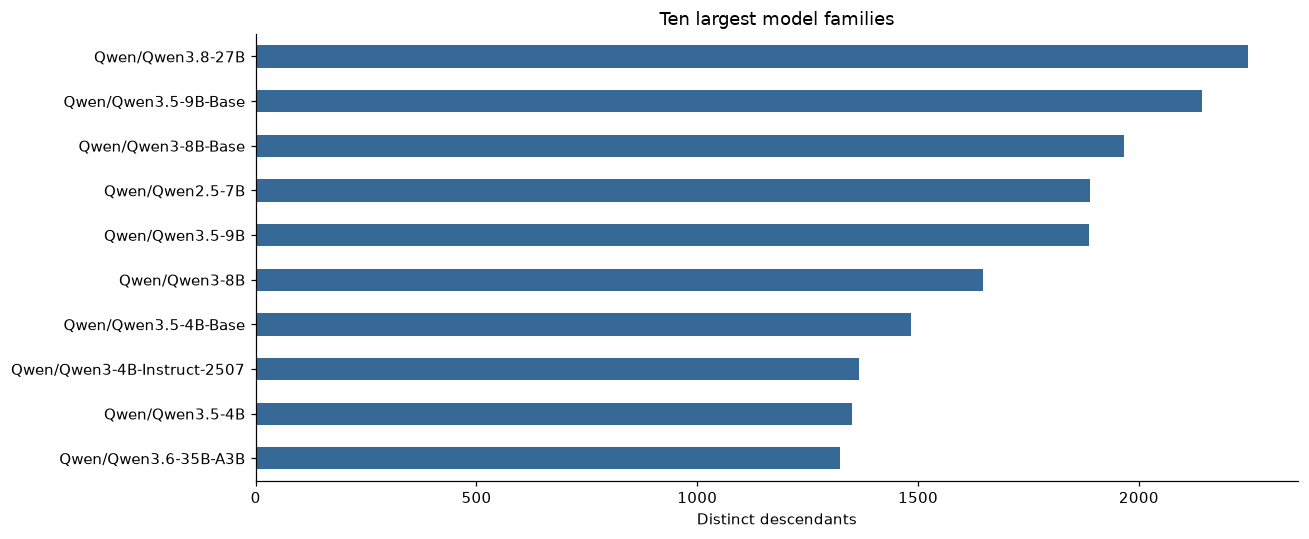

In [4]:
families = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.descendant_count IS NOT NULL "
        "RETURN m.id AS model, m.descendant_count AS descendants "
        "ORDER BY descendants DESC, model LIMIT $limit",
        limit=10,
    )
)
fig, axis = plt.subplots(figsize=(12, 5))
families.iloc[::-1].plot.barh(x="model", y="descendants", ax=axis, legend=False, color="#376996")
axis.set(title="Ten largest model families", xlabel="Distinct descendants", ylabel="")
fig.tight_layout()
plt.show()


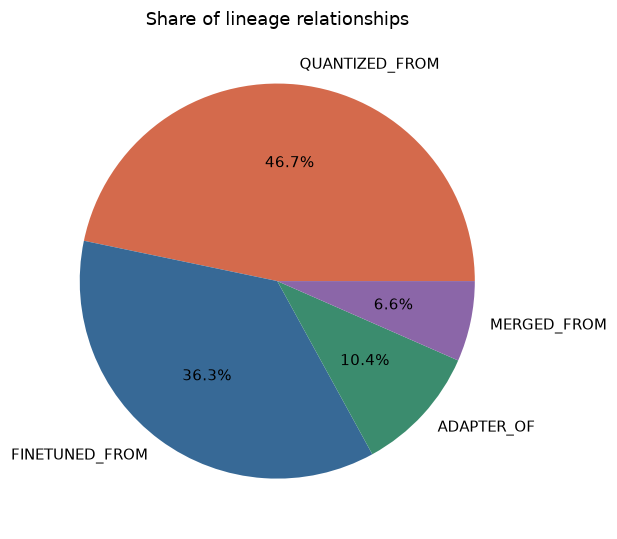

In [5]:
relation_colors = {
    "FINETUNED_FROM": "#376996",
    "ADAPTER_OF": "#3b8c6e",
    "QUANTIZED_FROM": "#d46a4c",
    "MERGED_FROM": "#8b66a8",
}
lineage_types = pd.DataFrame(
    read(
        "MATCH ()-[r]->() WHERE type(r) IN $relations "
        "RETURN type(r) AS relation, count(*) AS links ORDER BY links DESC, relation LIMIT $limit",
        relations=list(relation_colors),
        limit=4,
    )
)
fig, axis = plt.subplots(figsize=(8, 5))
axis.pie(
    lineage_types["links"],
    labels=lineage_types["relation"],
    autopct="%1.1f%%",
    colors=[relation_colors[kind] for kind in lineage_types["relation"]],
)
axis.set_title("Share of lineage relationships")
fig.tight_layout()
plt.show()


## 4. A small Mistral family tree

The API selects the 12 most downloaded descendants within two hops of
`mistralai/Mistral-7B-v0.1`. We then read their real graph paths and include
any connecting parent. This is a bounded sample, not the whole family.
Arrows point **from child to parent**, matching the stored relationships;
edge color shows the relation kind. Numbered labels identify the table below.

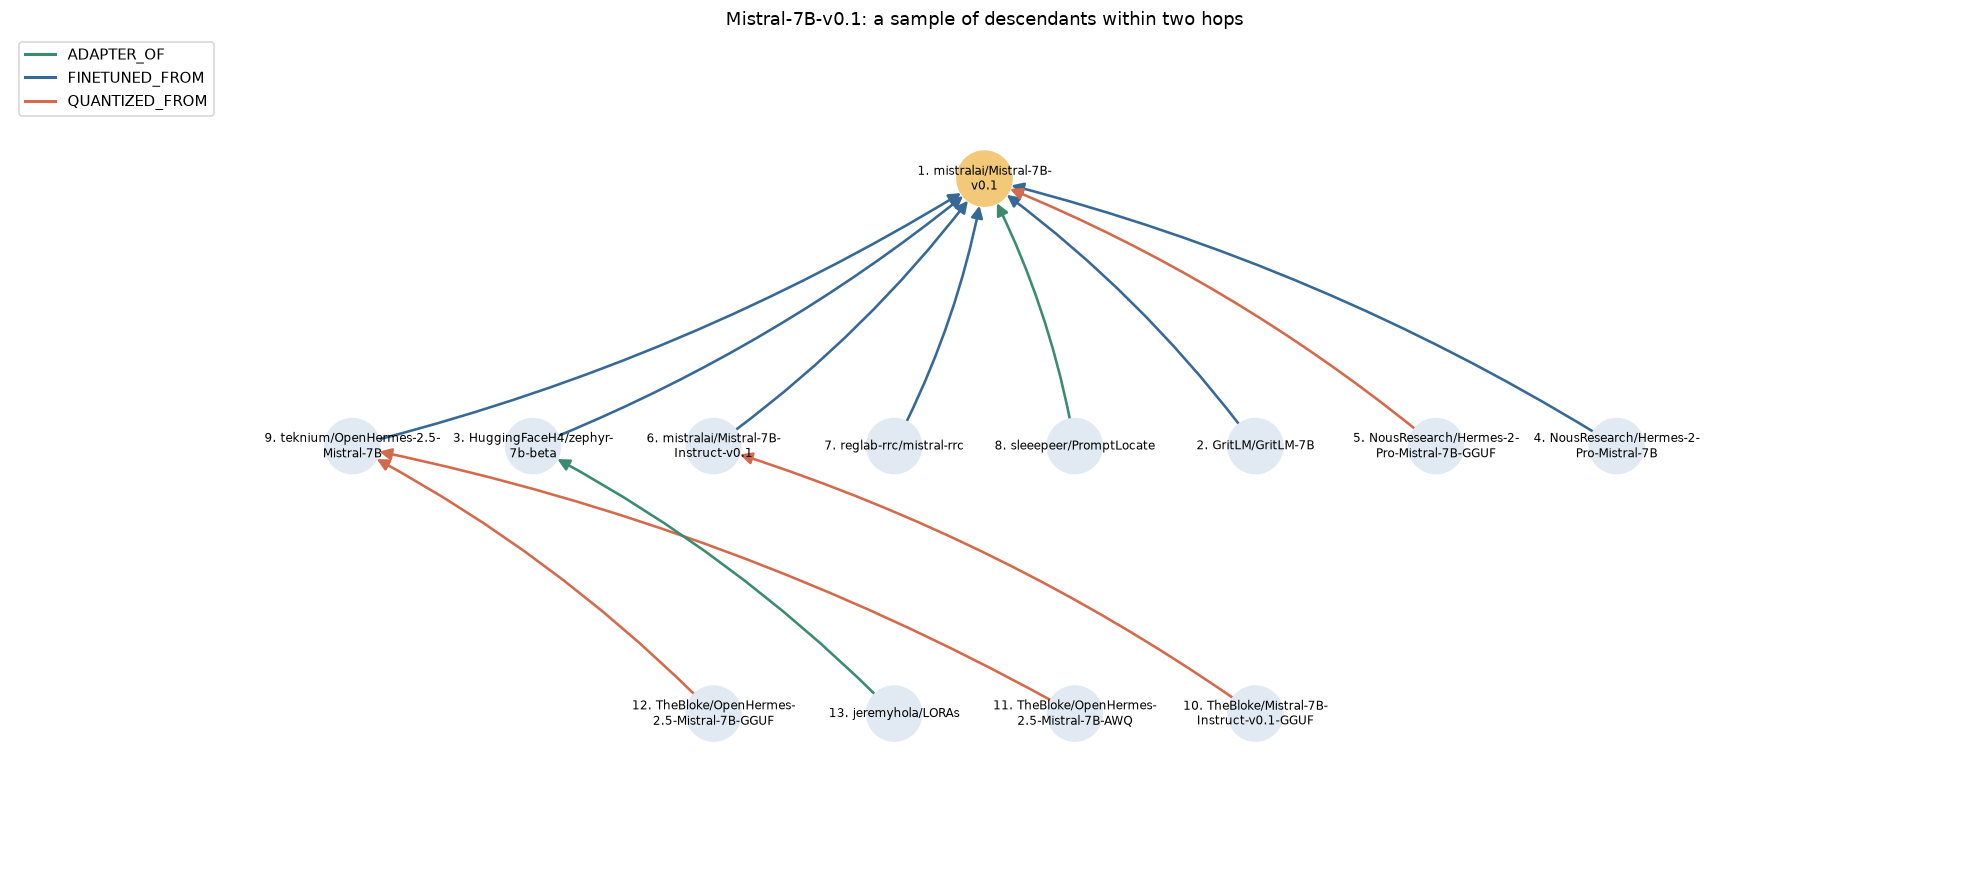

,number,model,distance from root
0,1,mistralai/Mistral-7B-v0.1,0
1,2,GritLM/GritLM-7B,1
2,3,HuggingFaceH4/zephyr-7b-beta,1
3,4,NousResearch/Hermes-2-Pro-Mistral-7B,1
4,5,NousResearch/Hermes-2-Pro-Mistral-7B-GGUF,1
5,6,mistralai/Mistral-7B-Instruct-v0.1,1
6,7,reglab-rrc/mistral-rrc,1
7,8,sleeepeer/PromptLocate,1
8,9,teknium/OpenHermes-2.5-Mistral-7B,1
9,10,TheBloke/Mistral-7B-Instruct-v0.1-GGUF,2


API sample: 12 descendants; drawing includes 13 nodes and 12 real edges.


In [6]:
import textwrap
from matplotlib.lines import Line2D

family_root = "mistralai/Mistral-7B-v0.1"
page = api(f"/models/{quote(family_root, safe='/')}/descendants", depth=2, limit=12)
selected = [item["model"]["id"] for item in page["items"]]
assert selected, "The full graph must contain descendants of the selected Mistral model."
paths = read(
    "MATCH p=(child:Model)-[:FINETUNED_FROM|ADAPTER_OF|QUANTIZED_FROM|MERGED_FROM*1..2]"
    "->(root:Model {id:$root}) WHERE child.id IN $ids "
    "RETURN [node IN nodes(p) | node.id] AS models, "
    "[rel IN relationships(p) | type(rel)] AS relations LIMIT $limit",
    root=family_root,
    ids=selected,
    limit=100,
)
tree = nx.MultiDiGraph()
for path in sorted(paths, key=lambda item: (item["models"], item["relations"])):
    for child, parent, kind in zip(path["models"], path["models"][1:], path["relations"]):
        tree.add_edge(child, parent, key=kind, relation=kind)
assert set(selected) <= set(tree.nodes), "Increase the bounded path sample if a selected model is missing."
levels = nx.single_source_shortest_path_length(tree.to_undirected(), family_root)
nx.set_node_attributes(tree, levels, "level")
positions = nx.multipartite_layout(tree, subset_key="level", align="horizontal")
positions = {node: (position[0], -position[1]) for node, position in positions.items()}
ordered = sorted(tree, key=lambda node: (levels[node], node))
labels = {node: f"{index}. " + "\n".join(textwrap.wrap(node, 23)) for index, node in enumerate(ordered, 1)}
colors = [relation_colors[kind] for _, _, kind in tree.edges(keys=True)]

fig, axis = plt.subplots(figsize=(18, 8))
nx.draw_networkx(
    tree,
    pos=positions,
    labels=labels,
    ax=axis,
    node_size=1300,
    node_color=["#f2c879" if node == family_root else "#e1eaf2" for node in tree],
    edge_color=colors,
    font_size=8,
    arrowsize=16,
    width=1.7,
    connectionstyle=["arc3,rad=0.08", "arc3,rad=-0.08"],
)
kinds = sorted({attributes["relation"] for _, _, attributes in tree.edges(data=True)})
axis.legend(
    handles=[Line2D([0], [0], color=relation_colors[kind], label=kind, lw=2) for kind in kinds], loc="upper left"
)
axis.set_title("Mistral-7B-v0.1: a sample of descendants within two hops")
axis.margins(0.2)
axis.axis("off")
fig.tight_layout()
plt.show()
display(
    pd.DataFrame(
        {
            "number": range(1, len(ordered) + 1),
            "model": ordered,
            "distance from root": [levels[node] for node in ordered],
        }
    )
)
print(
    f"API sample: {len(selected)} descendants; drawing includes {len(tree)} nodes and {tree.number_of_edges()} real edges."
)


In [7]:
driver.close()
http.close()
elapsed = perf_counter() - started
print(f"Analysis completed in {elapsed:.1f} seconds; connections closed.")
assert elapsed < 120, "The demo should finish in less than two minutes on the prepared stack."


Analysis completed in 6.4 seconds; connections closed.
